# Constants and configs

In [1]:
from typing import Final, Literal

from desakota.crs import CRS_UTM
from desakota.paths import DataLayout

LEVEL: Literal['DISTRICT', 'COMMUNE'] = 'COMMUNE'  # GADM admin level 2 or 3; drives input + output

TIME_RANGE: Final = '2023-01-02/2023-12-31'
BUILT_AREA_LABEL: Final = 'Built area'
WATER_LABEL: Final = 'Water'

layout = DataLayout.from_env().ensure()

GADM_PATHS: Final = {
    'DISTRICT': layout.raw / 'gadm41_VNM_2.json',
    'COMMUNE': layout.raw / 'gadm41_VNM_3.json',
}
# GADM's GID_n / NAME_n, renamed once at load (README "Naming conventions"). Level-2
# files have no *_3 columns; `rename` skips the absent keys.
GADM_COLUMNS: Final = {
    'GID_1': 'province_id',
    'NAME_1': 'province_name',
    'GID_2': 'district_id',
    'NAME_2': 'district_name',
    'GID_3': 'commune_id',
    'NAME_3': 'commune_name',
}
OUTPUT_STEM: Final = f'{LEVEL.lower()}s_built_frac'  # communes_built_frac / districts_built_frac

provinces = [
    'HàNội',
    'HảiPhòng',
    'HảiDương',
    'BắcNinh',
    'HưngYên',
    'HàNam',
    'NamĐịnh',
    'TháiBình',
    'NinhBình',
]

# Visualise the area of interest

,province_id,province_name,district_id,district_name,commune_id,commune_name,geometry
0,VNM.5_1,BắcNinh,VNM.5.1_1,BắcNinh,VNM.5.1.1_1,ĐạiPhúc,"MULTIPOLYGON (((610799.971 2341622.708, 611063..."
1,VNM.5_1,BắcNinh,VNM.5.1_1,BắcNinh,VNM.5.1.2_1,ĐápCầu,"MULTIPOLYGON (((613173.523 2345236.449, 614836..."
2,VNM.5_1,BắcNinh,VNM.5.1_1,BắcNinh,VNM.5.1.3_1,HạpLĩnh,"MULTIPOLYGON (((610116.346 2336714.389, 610123..."
3,VNM.5_1,BắcNinh,VNM.5.1_1,BắcNinh,VNM.5.1.4_1,HòaLong,"MULTIPOLYGON (((610772.395 2347256.879, 611462..."
4,VNM.5_1,BắcNinh,VNM.5.1_1,BắcNinh,VNM.5.1.5_1,KhắcNiệm,"MULTIPOLYGON (((611717.636 2339503.575, 611669..."
...,...,...,...,...,...,...,...
2131,VNM.55_1,TháiBình,VNM.55.8_1,VũThư,VNM.55.8.26_1,VũThư,"MULTIPOLYGON (((635253.377 2260109.671, 634607..."
2132,VNM.55_1,TháiBình,VNM.55.8_1,VũThư,VNM.55.8.27_1,VũTiến,"MULTIPOLYGON (((633447.119 2253553.548, 634150..."
2133,VNM.55_1,TháiBình,VNM.55.8_1,VũThư,VNM.55.8.28_1,VũVân,"MULTIPOLYGON (((641408.807 2251348.007, 640817..."
2134,VNM.55_1,TháiBình,VNM.55.8_1,VũThư,VNM.55.8.29_1,VũVinh,"MULTIPOLYGON (((641896.822 2256720.79, 642265...."


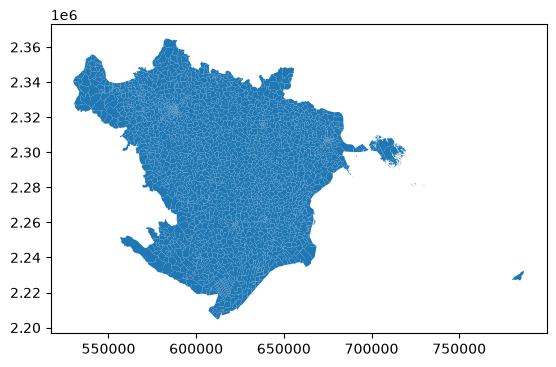

In [2]:
import geopandas as gpd

# GADM ships EPSG:4326. Keep the RRD provinces and only the renamed ID/name columns.
vnm_units_wgs84 = gpd.read_file(GADM_PATHS[LEVEL]).rename(columns=GADM_COLUMNS)
keep = [col for col in GADM_COLUMNS.values() if col in vnm_units_wgs84.columns]
admin_units_wgs84 = vnm_units_wgs84.loc[
    vnm_units_wgs84['province_name'].isin(provinces), [*keep, 'geometry']
].reset_index(drop=True)
admin_units = admin_units_wgs84.to_crs(CRS_UTM)  # canonical working CRS from here on

admin_units.plot()
admin_units

# Get the planetary info

In [3]:
from desakota.stac import create_client, get_bbox_from_aoi, get_collection, search_items

client = create_client()
collection = get_collection(client, '10M_ANNUAL_LANDUSE')

bbox_wgs84 = get_bbox_from_aoi(admin_units_wgs84)  # STAC bbox wants EPSG:4326 lon/lat

items = search_items(
    client,
    collection,
    bbox=bbox_wgs84,
    datetime=TIME_RANGE,
).items()

items = list(items)
# Each item is a whole UTM-zone x latitude-band mosaic (the delta sits in 48Q), so one
# year should yield exactly one item. More would mean the AOI spans several tiles,
# which fetch_landcover refuses rather than silently clipping a partial raster.
assert len(items) == 1, [item.id for item in items]
lulc_item = items[0]
lulc_item.id

'48Q-2023'

In [4]:
from desakota.landcover import fetch_landcover

# Windowed read of only the AOI's pixels from the remote COG, cached under raw/lulc
# with a JSON sidecar (item id, unsigned href, window). Reuses the file on rerun.
lulc_path = fetch_landcover(admin_units, lulc_item, cache_dir=layout.raw / 'lulc')
lulc_path

PosixPath('/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/data/raw/lulc/lulc_48Q-2023_30be6675327e.tif')

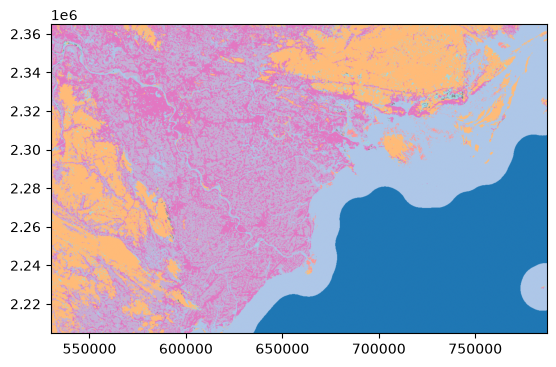

<Axes: >

In [5]:
import rasterio
from rasterio.plot import show

PREVIEW_STEP_PX = 20  # 200 m preview; default nearest-neighbour keeps class values intact

with rasterio.open(lulc_path) as lulc_src:
    assert lulc_src.crs == admin_units.crs  # vector-meets-raster boundary
    preview = lulc_src.read(
        1, out_shape=(lulc_src.height // PREVIEW_STEP_PX, lulc_src.width // PREVIEW_STEP_PX)
    )
    preview_transform = lulc_src.transform * lulc_src.transform.scale(
        lulc_src.width / preview.shape[1], lulc_src.height / preview.shape[0]
    )

ax = show(preview, transform=preview_transform, cmap='tab20')
admin_units.boundary.plot(ax=ax, color='black', linewidth=0.1)

# Overview of the raster data

In [6]:
from desakota.landcover import compute_built_frac, get_landcover_legend

legend = get_landcover_legend(collection)

admin_units['built_frac'] = compute_built_frac(
    aoi=admin_units,
    raster_path=lulc_path,
    legend=legend,
    built_area_label=BUILT_AREA_LABEL,
    water_label=WATER_LABEL,
)

<Axes: >

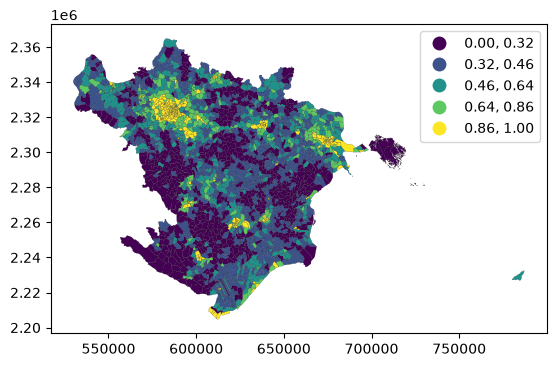

In [7]:
admin_units.plot(
    column='built_frac', legend=True, edgecolor='black', linewidth=0.1, scheme='FisherJenks'
)

# Persist processed data

In [8]:
admin_units.to_file(layout.processed / f'{OUTPUT_STEM}.gpkg', layer=OUTPUT_STEM, driver='GPKG')